In [73]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

In [74]:
df=pd.read_parquet("../data/bronze/oil.parquet")
df

,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-07,93.20
...,...,...
1213,2017-08-25,47.65
1214,2017-08-28,46.40
1215,2017-08-29,46.46
1216,2017-08-30,45.96


In [75]:
df.shape

(1218, 2)

In [76]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        1218 non-null   str    
 1   dcoilwtico  1175 non-null   float64
dtypes: float64(1), str(1)
memory usage: 31.1 KB


### MEMORIA

In [77]:
from pandas.api.types import is_float_dtype
def memoria():
    df["date"]=pd.to_datetime(df["date"])
    if is_float_dtype(df["dcoilwtico"]):
        df["dcoilwtico"]=pd.to_numeric(df["dcoilwtico"],downcast="float")
    return df


df=memoria()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        1218 non-null   datetime64[us]
 1   dcoilwtico  1175 non-null   float32       
dtypes: datetime64[us](1), float32(1)
memory usage: 14.4 KB


### RELLENADO DE VALORES NULL

<Axes: >

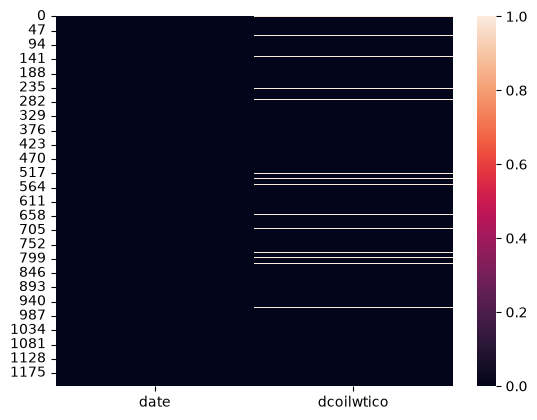

In [78]:
sns.heatmap(df.isnull())

In [79]:
df.describe()

,date,dcoilwtico
count,1218,1175.000000
mean,2015-05-02 12:00:00,67.714363
min,2013-01-01 00:00:00,26.190001
25%,2014-03-03 06:00:00,46.404999
50%,2015-05-02 12:00:00,53.189999
75%,2016-06-30 18:00:00,95.660004
max,2017-08-31 00:00:00,110.620003
std,NaN,25.630476


In [80]:
df["dcoilwtico"]=df["dcoilwtico"].fillna(df["dcoilwtico"].median())

In [81]:
df.describe()

,date,dcoilwtico
count,1218,1218.000000
mean,2015-05-02 12:00:00,67.201599
min,2013-01-01 00:00:00,26.190001
25%,2014-03-03 06:00:00,46.700001
50%,2015-05-02 12:00:00,53.189999
75%,2016-06-30 18:00:00,95.332499
max,2017-08-31 00:00:00,110.620003
std,NaN,25.316023


In [82]:
df.isnull().sum()

date          0
dcoilwtico    0
dtype: int64

In [83]:
df.duplicated().sum()

np.int64(0)

### OUTLIERS

<Axes: >

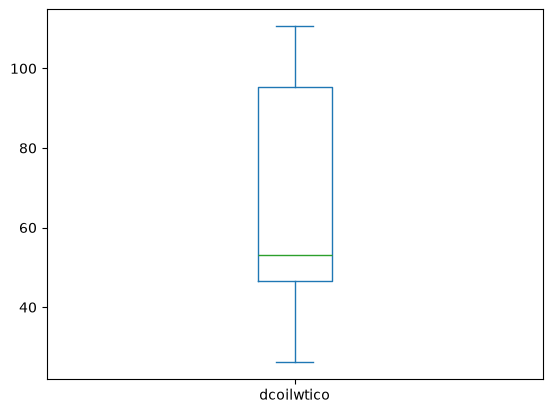

In [84]:
df["dcoilwtico"].plot(kind="box",sharey=False,sharex=False)

## EDA PROFUNDO

### DCOILWTICO

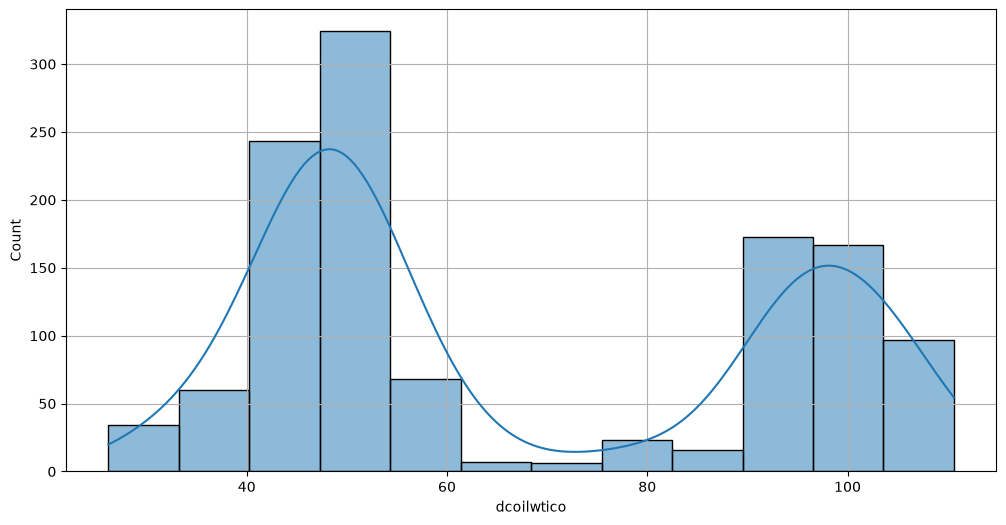

In [85]:
plt.figure(figsize=(12,6))
sns.histplot(data=df,x="dcoilwtico",kde=True)
plt.grid()

In [86]:
print(f"Promedio de dcoilwtico: {df["dcoilwtico"].mean():.2f}")
print(f"Median de decoilwtico: {df["dcoilwtico"].median():.2f}")

Promedio de dcoilwtico: 67.20
Median de decoilwtico: 53.19


In [87]:
print(f"Asimetria: {df["dcoilwtico"].skew():.2f}")
print(f"Curtosis: {df["dcoilwtico"].kurt():.2f}")

Asimetria: 0.38
Curtosis: -1.56


/tmp/ipykernel_3125/764395268.py:1: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index("date",inplace=True)


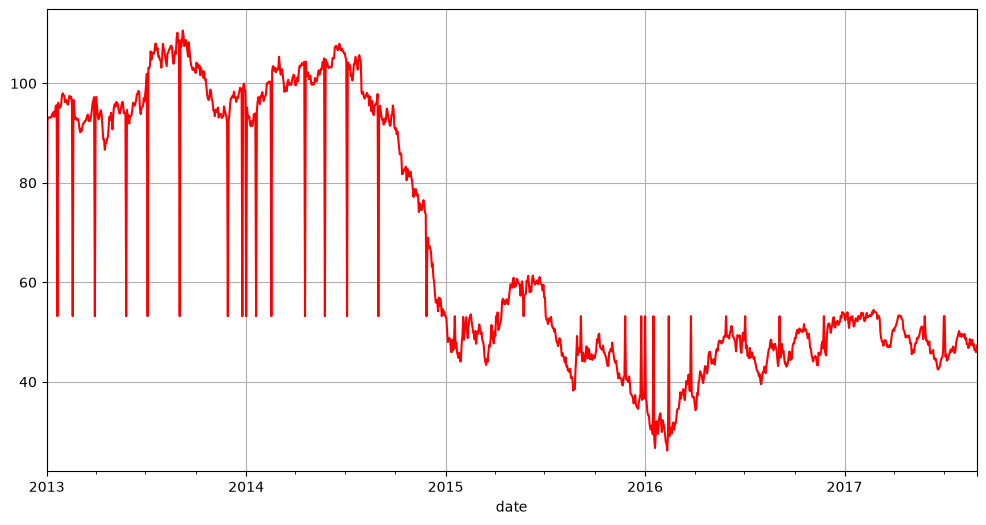

In [88]:
df.set_index("date",inplace=True)
df["dcoilwtico"].plot(figsize=(12,6),color="red")
plt.grid()

In [89]:
df.to_csv("../data/silver/oil.csv",index=False,encoding="utf-8-sig")